# Hugging Face Hub, NumPy Convolution & Pooling, and a CNN for CIFAR-10

**Google Colab practical notebook**

This notebook covers:
1. Hugging Face Hub, datasets, and model cards.
2. Loading and exploring an image dataset.
3. Implementing 2D convolution and max-pooling from scratch using NumPy.
4. Understanding kernel size, stride, and padding.
5. Building, training, and evaluating a basic CNN for CIFAR-10 classification.

> **Suggested runtime:** Google Colab → Runtime → Change runtime type → T4 GPU (optional; CPU also works, but training will be slower).

**Learning outcomes**
- Explain what the Hugging Face Hub stores and how model cards help users.
- Load a dataset with the `datasets` library.
- Calculate convolution and pooling output dimensions.
- Implement convolution and max-pooling without deep-learning libraries.
- Train a CNN to classify the 10 CIFAR-10 image categories.


## 1. Hugging Face Hub: introduction

[Hugging Face](https://huggingface.co/) is a platform and open-source ecosystem for sharing and using machine-learning resources.

### What is the Hugging Face Hub?
The **Hugging Face Hub** is a central repository where the community can publish, discover, version, and collaborate on:
- **Models:** trained model weights and configuration files.
- **Datasets:** datasets and dataset documentation.
- **Spaces:** interactive machine-learning demos and applications.

### Important concepts
| Concept | Meaning |
|---|---|
| Repository | A project space containing files and version history |
| Model repository | Stores model weights, configuration, tokenizer/processor files, and documentation |
| Dataset repository | Stores dataset files, metadata, and loading instructions |
| Model card | A README-style document describing a model, its intended use, evaluation, limitations, and risks |
| Dataset card | Documentation describing a dataset, its contents, collection process, intended uses, and limitations |
| `transformers` | Library for using many pretrained transformer models |
| `datasets` | Library for downloading, processing, and streaming datasets |
| `huggingface_hub` | Python library for interacting with Hub repositories |

### Why are model cards important?
A model card helps a user decide whether a model is appropriate and safe for a task. A good model card typically includes:
- Model description and architecture.
- Intended use and out-of-scope use.
- Training data and training procedure.
- Evaluation results and metrics.
- Known limitations and potential biases.
- License, authors, and citation information.

**Important:** A model card is documentation, not proof that a model is accurate or unbiased. Always inspect the evidence and license before using a model.

In [8]:
# Install the Hugging Face libraries used in this section
!pip -q install -U datasets huggingface_hub

In [9]:

# Step 1: Install Hugging Face Hub
!pip install -U huggingface_hub

# Step 2: Import library
from huggingface_hub import HfApi

# Step 3: Initialize API
api = HfApi()

# Step 4: Search image classification models
results = api.list_models(
    filter="image-classification",
    sort="downloads",
    limit=10
)

# Step 5: Display results
print("\nTOP 10 IMAGE CLASSIFICATION MODELS")
print("=" * 70)

for i, model in enumerate(results, start=1):

    print(f"\nRank: {i}")
    print(f"Model Name: {model.modelId}")
    print(f"Downloads: {model.downloads}")
    print(f"Likes: {model.likes}")
    print(f"Model URL: https://huggingface.co/{model.modelId}")

    print("-" * 70)



TOP 10 IMAGE CLASSIFICATION MODELS

Rank: 1
Model Name: google/vit-base-patch16-224
Downloads: 16245542
Likes: 1049
Model URL: https://huggingface.co/google/vit-base-patch16-224
----------------------------------------------------------------------

Rank: 2
Model Name: timm/mobilenetv3_small_100.lamb_in1k
Downloads: 14873217
Likes: 157
Model URL: https://huggingface.co/timm/mobilenetv3_small_100.lamb_in1k
----------------------------------------------------------------------

Rank: 3
Model Name: prithivMLmods/Gender-Classifier-Mini
Downloads: 9776496
Likes: 19
Model URL: https://huggingface.co/prithivMLmods/Gender-Classifier-Mini
----------------------------------------------------------------------

Rank: 4
Model Name: timm/tf_efficientnetv2_s.in21k_ft_in1k
Downloads: 3605262
Likes: 16
Model URL: https://huggingface.co/timm/tf_efficientnetv2_s.in21k_ft_in1k
----------------------------------------------------------------------

Rank: 5
Model Name: timm/resnet18.a1_in1k
Downloads: 207

### Inspect a model repository and its model card

The following cell retrieves metadata for a public model. The model ID is an example; you can replace it with another image-classification model found on the Hub.

In [10]:
model_id = "google/vit-base-patch16-224"
info = model_info(model_id)

print("Model:", info.id)
print("Pipeline tag:", info.pipeline_tag)
print("Library:", info.library_name)
print("Downloads:", info.downloads)
print("Likes:", info.likes)
print("\nModel card / README preview:")
if info.card_data:
    print(info.card_data)
else:
    print("No structured card metadata was returned. Open the model page to read its README/model card.")

Model: google/vit-base-patch16-224
Pipeline tag: image-classification
Library: transformers
Downloads: 16245542
Likes: 1049

Model card / README preview:
datasets:
- imagenet-1k
- imagenet-21k
license: apache-2.0
tags:
- vision
- image-classification
widget:
- src: https://huggingface.co/datasets/mishig/sample_images/resolve/main/tiger.jpg
  example_title: Tiger
- src: https://huggingface.co/datasets/mishig/sample_images/resolve/main/teapot.jpg
  example_title: Teapot
- src: https://huggingface.co/datasets/mishig/sample_images/resolve/main/palace.jpg
  example_title: Palace


**Explore manually:** open the model page at `https://huggingface.co/google/vit-base-patch16-224` and review its README/model card, license, intended use, limitations, and evaluation information.

## 2. Loading a dataset from Hugging Face

The 🤗 `datasets` library provides a consistent interface for loading public datasets. It supports dataset caching, splits, filtering, mapping, and streaming.

For this notebook we use **CIFAR-10**, a standard image-classification dataset:
- 60,000 colour images.
- Image dimensions: 32 × 32 pixels, with 3 colour channels (RGB).
- 10 classes.
- 50,000 training images and 10,000 test images in the standard split.

The class labels are: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, and truck.

In [11]:
!pip -q install -U datasets pillow matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [12]:
from datasets import load_dataset

# Load CIFAR-10 from the Hugging Face Hub.
# The dataset is cached after the first download.
dataset = load_dataset("uoft-cs/cifar10")

print(dataset)
print("Train rows:", len(dataset["train"]))
print("Test rows:", len(dataset["test"]))
print("Features:", dataset["train"].features)

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['img', 'label'],
        num_rows: 50000
    })
    test: Dataset({
        features: ['img', 'label'],
        num_rows: 10000
    })
})
Train rows: 50000
Test rows: 10000
Features: {'img': Image(mode=None, decode=True), 'label': ClassLabel(names=['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck'])}


dict_keys(['img', 'label'])
Label: 0


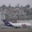

In [13]:
# Inspect one sample
sample = dataset["train"][0]
print(sample.keys())
print("Label:", sample["label"])
display(sample["img"])

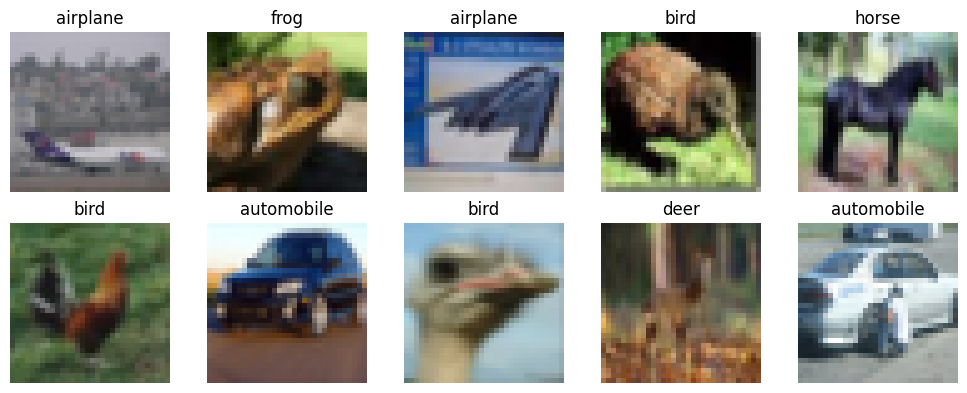

In [14]:
import matplotlib.pyplot as plt

class_names = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

plt.figure(figsize=(10, 4))
for i in range(10):
    item = dataset["train"][i]
    plt.subplot(2, 5, i + 1)
    plt.imshow(item["img"])
    plt.title(class_names[item["label"]])
    plt.axis("off")
plt.tight_layout()
plt.show()

### Convert the dataset to NumPy arrays

The CNN section below uses PyTorch tensors, but first we convert a subset of the Hugging Face dataset into NumPy arrays to understand the image layout and pixel values. The full training set is used later.

In [15]:
import numpy as np

def image_to_array(image):
    # Convert PIL image to uint8 NumPy array: (height, width, channels)
    return np.asarray(image.convert("RGB"), dtype=np.uint8)

x_example = image_to_array(dataset["train"][0]["img"])
y_example = dataset["train"][0]["label"]

print("Image shape (H, W, C):", x_example.shape)
print("Image dtype:", x_example.dtype)
print("Label:", y_example, "=", class_names[y_example])
print("Pixel range:", x_example.min(), "to", x_example.max())

Image shape (H, W, C): (32, 32, 3)
Image dtype: uint8
Label: 0 = airplane
Pixel range: 34 to 203


## 3. Convolution using NumPy

A **convolution** operation applies a small matrix called a **kernel** (or filter) to an input image.

At each location:
1. Place the kernel over a local image region.
2. Multiply corresponding values.
3. Add all products.
4. Store the sum in the output feature map.

For a single-channel image \(I\) and kernel \(K\), the operation commonly used in CNN libraries is technically cross-correlation (the kernel is not flipped):

\[
O(i,j)=\\sum_{m=0}^{K_h-1}\\sum_{n=0}^{K_w-1}
I(iS+m-P,\ jS+n-P)K(m,n)
\]

Here \(S\) is stride and \(P\) is padding. Out-of-image values are treated as zero when zero-padding is used.

### Output-size formula

For input height \(H\), kernel height \(K\), padding \(P\), and stride \(S\):

\[
H_{out}=\\left\\lfloor\\frac{H+2P-K}{S}\\right\\rfloor+1
\]

Similarly,

\[
W_{out}=\\left\\lfloor\\frac{W+2P-K_w}{S}\\right\\rfloor+1
\]

- **Kernel size:** size of the filter, e.g. 3 × 3.
- **Stride:** number of pixels the filter moves at each step.
- **Padding:** extra border pixels added around the input. Zero-padding is common.
- **Valid padding:** no padding (`P=0`).
- **Same-style padding:** often chosen to preserve spatial dimensions when stride is 1 and the kernel size is odd (`P=(K-1)/2`).

In [16]:
import numpy as np

def conv2d_numpy(image, kernel, stride=1, padding=0):
    """2D cross-correlation for a single-channel 2D image."""
    image = np.asarray(image, dtype=float)
    kernel = np.asarray(kernel, dtype=float)

    if image.ndim != 2 or kernel.ndim != 2:
        raise ValueError("image and kernel must both be 2D arrays")
    if stride < 1 or padding < 0:
        raise ValueError("stride must be >= 1 and padding must be >= 0")

    h, w = image.shape
    kh, kw = kernel.shape
    padded = np.pad(image, ((padding, padding), (padding, padding)),
                    mode="constant")
    out_h = (h + 2 * padding - kh) // stride + 1
    out_w = (w + 2 * padding - kw) // stride + 1
    if out_h <= 0 or out_w <= 0:
        raise ValueError("Kernel is larger than the padded input")

    output = np.zeros((out_h, out_w), dtype=float)
    for i in range(out_h):
        for j in range(out_w):
            region = padded[i*stride:i*stride+kh,
                            j*stride:j*stride+kw]
            output[i, j] = np.sum(region * kernel)
    return output

# A small example image and edge-detection kernel
image = np.array([
    [1, 2, 3, 0, 1],
    [4, 5, 6, 1, 2],
    [7, 8, 9, 2, 3],
    [1, 2, 3, 4, 5],
    [0, 1, 2, 3, 4]
], dtype=float)

kernel = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
], dtype=float)

result = conv2d_numpy(image, kernel, stride=1, padding=0)
print("Input shape:", image.shape)
print("Kernel shape:", kernel.shape)
print("Output shape:", result.shape)
print(result)

Input shape: (5, 5)
Kernel shape: (3, 3)
Output shape: (3, 3)
[[  6. -12. -12.]
 [  6.  -8.  -8.]
 [  6.  -2.  -2.]]


### Visualise convolution

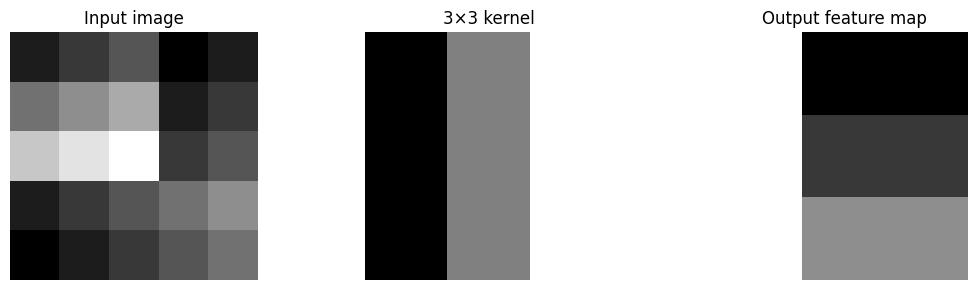

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
axes[0].imshow(image, cmap="gray")
axes[0].set_title("Input image")
axes[1].imshow(kernel, cmap="gray")
axes[1].set_title("3×3 kernel")
axes[2].imshow(result, cmap="gray")
axes[2].set_title("Output feature map")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### Experiment with kernel size, stride, and padding

Try changing the kernel, stride, and padding below. Notice how the output dimensions change.

In [18]:
# Use a 3x3 averaging kernel as an example
average_kernel = np.ones((3, 3), dtype=float) / 9

for stride, padding in [(1, 0), (1, 1), (2, 0), (2, 1)]:
    out = conv2d_numpy(image, average_kernel, stride=stride, padding=padding)
    print(f"stride={stride}, padding={padding} -> output shape {out.shape}")

stride=1, padding=0 -> output shape (3, 3)
stride=1, padding=1 -> output shape (5, 5)
stride=2, padding=0 -> output shape (2, 2)
stride=2, padding=1 -> output shape (3, 3)


**Worked shape example**

Input = 32 × 32, kernel = 3 × 3.

- Stride 1, padding 0: \((32-3)/1+1=30\), so output = 30 × 30.
- Stride 1, padding 1: \((32+2-3)/1+1=32\), so output = 32 × 32.
- Stride 2, padding 0: \(\lfloor(32-3)/2\rfloor+1=15\), so output = 15 × 15.

A larger stride reduces spatial resolution. Padding helps preserve border information and can preserve the output size.

## 4. Max-pooling using NumPy

**Max-pooling** reduces the spatial size of a feature map. It divides the input into local windows and keeps only the largest value in each window.

For a 2 × 2 window and stride 2, each non-overlapping 2 × 2 region becomes one output value. Max-pooling has no trainable weights.

The output-size formula is the same form as convolution:

\[
H_{out}=\\left\\lfloor\\frac{H+2P-K_h}{S}\\right\\rfloor+1
\]

In this simple implementation, padding uses negative infinity so padded values cannot become the maximum.

In [19]:
def max_pool2d_numpy(image, pool_size=2, stride=2, padding=0):
    """Max-pooling for a single-channel 2D array."""
    image = np.asarray(image, dtype=float)
    if image.ndim != 2:
        raise ValueError("image must be a 2D array")
    if isinstance(pool_size, int):
        kh = kw = pool_size
    else:
        kh, kw = pool_size
    if stride < 1 or padding < 0:
        raise ValueError("stride must be >= 1 and padding must be >= 0")

    h, w = image.shape
    padded = np.pad(image, ((padding, padding), (padding, padding)),
                    mode="constant", constant_values=-np.inf)
    out_h = (h + 2 * padding - kh) // stride + 1
    out_w = (w + 2 * padding - kw) // stride + 1
    if out_h <= 0 or out_w <= 0:
        raise ValueError("Pooling window is larger than the padded input")

    output = np.empty((out_h, out_w), dtype=float)
    for i in range(out_h):
        for j in range(out_w):
            region = padded[i*stride:i*stride+kh,
                            j*stride:j*stride+kw]
            output[i, j] = np.max(region)
    return output

pool_input = np.array([
    [1, 3, 2, 4],
    [5, 6, 1, 2],
    [7, 2, 8, 3],
    [4, 9, 5, 6]
])

pooled = max_pool2d_numpy(pool_input, pool_size=2, stride=2)
print("Input:\n", pool_input)
print("Pooled output:\n", pooled)

Input:
 [[1 3 2 4]
 [5 6 1 2]
 [7 2 8 3]
 [4 9 5 6]]
Pooled output:
 [[6. 4.]
 [9. 8.]]


**Expected output:**
```text
[[6. 4.]
 [9. 8.]]
```

Each output is the maximum of one 2 × 2 region.

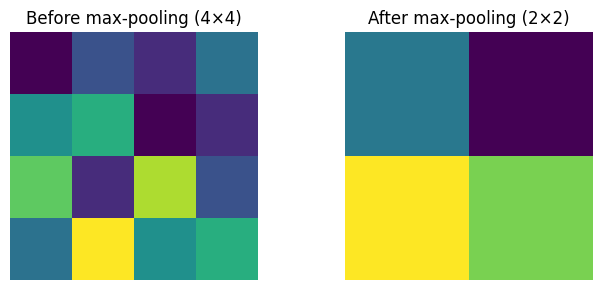

In [20]:
# Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].imshow(pool_input, cmap="viridis")
axes[0].set_title("Before max-pooling (4×4)")
axes[1].imshow(pooled, cmap="viridis")
axes[1].set_title("After max-pooling (2×2)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. From NumPy operations to a CNN

A **Convolutional Neural Network (CNN)** is a neural network designed especially for grid-like data such as images.

Typical CNN components:
1. **Convolution layer:** learns filters that detect patterns such as edges, textures, and shapes.
2. **Activation (ReLU):** introduces non-linearity using \(f(x)=\\max(0,x)\).
3. **Pooling layer:** reduces feature-map dimensions.
4. **Flatten:** converts feature maps into a one-dimensional vector.
5. **Fully connected layer:** combines learned features to predict a class.
6. **Loss function:** measures prediction error.
7. **Optimizer:** updates weights to reduce the loss.

The NumPy functions above demonstrate the core spatial operations. For efficient training, the next section uses PyTorch, which computes gradients and performs convolution on CPU/GPU.

## 6. Build a basic CNN for CIFAR-10

We will train a small CNN with two convolution blocks and a classifier.

**Architecture**
- Input: 3 × 32 × 32 RGB image.
- Conv(3 → 32, 3×3) + ReLU + MaxPool(2×2).
- Conv(32 → 64, 3×3) + ReLU + MaxPool(2×2).
- Flatten.
- Fully connected layer → 128 units + ReLU.
- Output layer → 10 class scores.

Images are normalized to the range 0–1. The network returns raw class scores (logits); `CrossEntropyLoss` applies the appropriate log-softmax internally.

In [21]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

print("PyTorch:", torch.__version__)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

PyTorch: 2.11.0+cpu
Using device: cpu


### Prepare CIFAR-10 from the Hugging Face dataset

This custom PyTorch dataset reads the already-loaded Hugging Face dataset and converts each image to a tensor. The standard train and test splits are used.

In [22]:
class HFCIFAR10TorchDataset(Dataset):
    def __init__(self, hf_split, transform=None):
        self.data = hf_split
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        row = self.data[index]
        image = row["img"].convert("RGB")
        label = int(row["label"])
        if self.transform:
            image = self.transform(image)
        return image, label

# Convert PIL images to float tensors with shape (C, H, W) and values in [0, 1].
transform = transforms.ToTensor()

train_dataset = HFCIFAR10TorchDataset(dataset["train"], transform=transform)
test_dataset = HFCIFAR10TorchDataset(dataset["test"], transform=transform)

# If Colab runs out of RAM, lower batch_size or use a smaller subset for practice.
batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size,
                          shuffle=True, num_workers=2, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_dataset, batch_size=batch_size,
                         shuffle=False, num_workers=2, pin_memory=torch.cuda.is_available())

images, labels = next(iter(train_loader))
print("Batch image shape:", images.shape)  # (batch, 3, 32, 32)
print("Batch label shape:", labels.shape)

Batch image shape: torch.Size([128, 3, 32, 32])
Batch label shape: torch.Size([128])


### Define the CNN

In [23]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = SimpleCNN().to(device)
print(model)

# Check the output shape with a dummy batch
with torch.no_grad():
    dummy = torch.zeros(4, 3, 32, 32).to(device)
    print("Output shape:", model(dummy).shape)  # (4, 10)

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Output shape: torch.Size([4, 10])


### Understand the feature-map dimensions

| Stage | Tensor shape (batch, channels, height, width) |
|---|---|
| Input | (B, 3, 32, 32) |
| Conv 3×3, padding 1 | (B, 32, 32, 32) |
| MaxPool 2×2, stride 2 | (B, 32, 16, 16) |
| Conv 3×3, padding 1 | (B, 64, 16, 16) |
| MaxPool 2×2, stride 2 | (B, 64, 8, 8) |
| Flatten | (B, 4096) |
| Dense | (B, 128) |
| Output | (B, 10) |

`B` is the batch size. The final 10 values are scores for the 10 CIFAR-10 classes.

### Train the CNN

In [24]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, 100.0 * correct / total

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        outputs = model(images)
        loss = criterion(outputs, labels)

        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, 100.0 * correct / total

# Start with 3 epochs for a quick practical demonstration.
# Increase to 10–20 epochs for a better result, especially when using a GPU.
epochs = 3
history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

for epoch in range(epochs):
    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )
    test_loss, test_acc = evaluate(model, test_loader, criterion, device)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["test_loss"].append(test_loss)
    history["test_acc"].append(test_acc)

    print(f"Epoch {epoch+1}/{epochs} | "
          f"train loss: {train_loss:.4f}, train acc: {train_acc:.2f}% | "
          f"test loss: {test_loss:.4f}, test acc: {test_acc:.2f}%")

Epoch 1/3 | train loss: 1.6460, train acc: 40.49% | test loss: 1.3042, test acc: 53.13%
Epoch 2/3 | train loss: 1.3109, train acc: 52.86% | test loss: 1.1483, test acc: 59.52%
Epoch 3/3 | train loss: 1.1709, train acc: 58.13% | test loss: 1.0394, test acc: 63.55%


### Plot training history

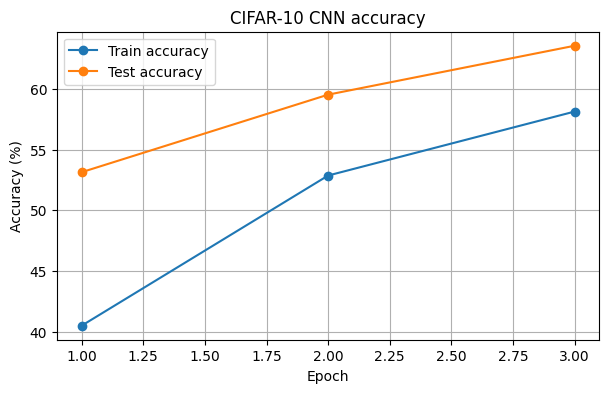

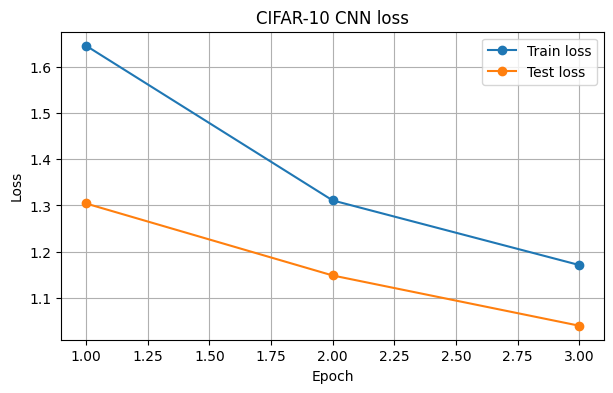

In [25]:
epochs_range = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(7, 4))
plt.plot(epochs_range, history["train_acc"], marker="o", label="Train accuracy")
plt.plot(epochs_range, history["test_acc"], marker="o", label="Test accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("CIFAR-10 CNN accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(epochs_range, history["train_loss"], marker="o", label="Train loss")
plt.plot(epochs_range, history["test_loss"], marker="o", label="Test loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CIFAR-10 CNN loss")
plt.legend()
plt.grid(True)
plt.show()

### Test predictions on sample images

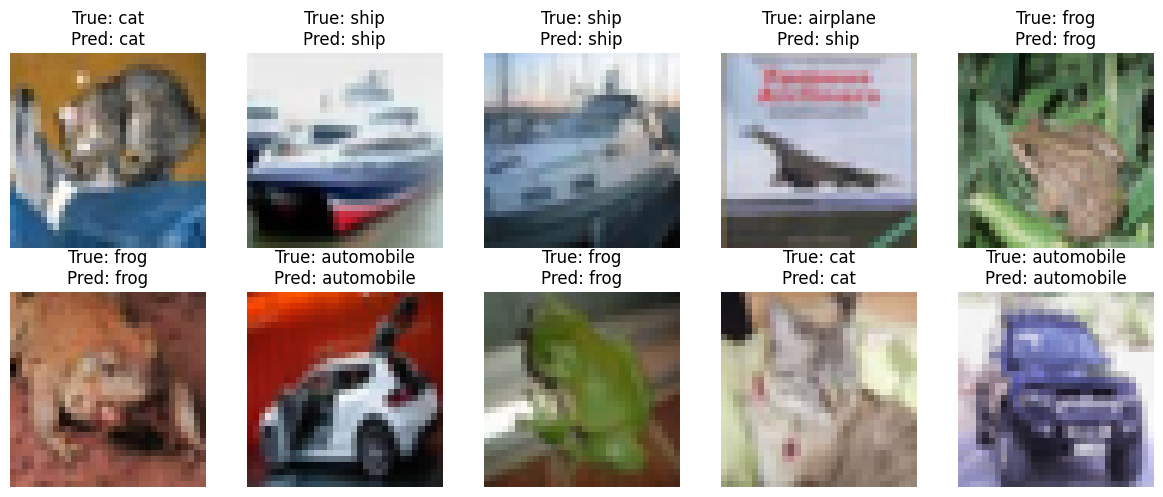

In [26]:
@torch.no_grad()
def show_predictions(model, loader, device, class_names, count=10):
    model.eval()
    images, labels = next(iter(loader))
    images_device = images[:count].to(device)
    outputs = model(images_device)
    predictions = outputs.argmax(dim=1).cpu()

    fig, axes = plt.subplots(2, 5, figsize=(12, 5))
    for i, ax in enumerate(axes.flat):
        img = images[i].permute(1, 2, 0).numpy()
        ax.imshow(img)
        true_name = class_names[int(labels[i])]
        pred_name = class_names[int(predictions[i])]
        ax.set_title(f"True: {true_name}\nPred: {pred_name}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_predictions(model, test_loader, device, class_names)

## 7. Save the trained model

In [27]:
# Save model weights to the Colab session.
torch.save(model.state_dict(), "cifar10_simple_cnn.pth")
print("Saved: cifar10_simple_cnn.pth")

# Optional: download the weights to your computer.
from google.colab import files
files.download("cifar10_simple_cnn.pth")

Saved: cifar10_simple_cnn.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Key comparison: convolution vs max-pooling

| Feature | Convolution | Max-pooling |
|---|---|---|
| Main purpose | Learn/extract image features | Reduce spatial dimensions |
| Trainable parameters | Yes (kernels and optional bias) | No |
| Operation | Multiply and sum | Select maximum |
| Typical example | 3×3 kernel, stride 1 | 2×2 window, stride 2 |
| Effect | Creates feature maps | Keeps strongest local activation |
